### Filter Verification V4.1

In [1]:
import os
import datetime as dt

from dotenv import load_dotenv
from pathlib import Path

import pywt
import json
import time
from urllib.parse import urljoin, urlencode
import requests

import numpy as np
import pandas as pd

import plotly
import plotly.graph_objs as go
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

import statsmodels.api as sm

from scipy.stats import spearmanr
from scipy.stats import pearsonr
from scipy.stats import linregress
from scipy.stats import fisher_exact
from scipy.signal import butter
from scipy.signal import lfilter
from sklearn.metrics import roc_auc_score
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.filters.hp_filter import hpfilter
from statsmodels.tsa.stattools import grangercausalitytests
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    roc_auc_score
)
from sklearn.feature_selection import (
    mutual_info_regression
)
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso
)

from pykalman import KalmanFilter
from tqdm import tqdm

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.request_api_v2 import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension
from Modules.fibonacci_retracement import FibonacciRetracement
from Modules.fibonacci_extension import FibonacciExtension

In [2]:
# FRED API key for accessing Federal Reserve Economic Data
FRED_API_KEY = os.getenv("FRED_API_KEY")
# Output directory for storing downloaded data
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
fred_url = "https://api.stlouisfed.org/fred/series/observations"
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()
# Fibonacciエクステンションをプロットするクラスのインスタンスを作成
fibonacci_extension_v2 = FibonacciExtension() 
# Fibonacciリトレースメントを計算するクラスのインスタンスを作成
fibonacci_retracement = FibonacciRetracement()

In [3]:
# Date range for fetching API s
start = '1950-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
frequency = "d"
aggregation_method = "avg"

In [4]:
def delete_column(df):
    df = df.drop(columns=['realtime_start', 'realtime_end', 'interest_rate_type'])
    return df

#### S&P500(均等加重)時系列を取得

In [5]:
spxew_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="^SPXEW",
    market=None,
    series_name="SPXEW"
))
spxew_df.tail()

取得件数: 4990


,value
date,
2026-10-26,8772.370117
2026-10-27,8802.639648
2026-10-28,8809.419922
2026-10-29,8806.370117
2026-10-30,8888.769531


#### S&P500(時価総額加重平均)時系列を取得

In [6]:
sp500_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="^GSPC",
    market=None,
    series_name="GSPC"
))
sp500_df.tail()

取得件数: 19360


,value
date,
2026-10-26,7639.700195
2026-10-27,7699.470215
2026-10-28,7735.560059
2026-10-29,7699.609863
2026-10-30,7631.069824


#### Nasdaq100(均等加重)時系列を取得

In [7]:
ndxe_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="^NDXE",
    market=None,
    series_name="NDXE"
))
ndxe_df.tail()

取得件数: 5151


,value
date,
2026-10-26,9917.309570
2026-10-27,10010.910156
2026-10-28,10064.759766
2026-10-29,10038.530273
2026-10-30,9927.026367


#### Nasdaq100(時価総額加重平均)時系列を取得

In [8]:
qqq_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="^IXIC",
    market=None,
    series_name="IXIC"
))
qqq_df.tail()

取得件数: 14052


,value
date,
2026-10-26,26026.869141
2026-10-27,26286.310547
2026-10-28,26541.609375
2026-10-29,26201.820312
2026-10-30,25592.486328


#### iShares iBoxx $ High Yield Corporate Bond ETF

In [9]:
hyg_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="HYG",
    market=None,
    series_name="HYG"
))
hyg_df.tail()

取得件数: 4922


,value
date,
2026-10-26,77.080002
2026-10-27,77.300003
2026-10-28,77.709999
2026-10-29,77.480003
2026-10-30,77.440002


#### iShares 7-10 Year Treasury Bond ETF (IEF)

In [10]:
ief_df = delete_column(request_api.fetch_stock_timeseries_data_fred_format(
    start_date=start,
    end_date=end,
    code="IEF",
    market=None,
    series_name="IEF"
))
ief_df.tail()

取得件数: 6104


,value
date,
2026-10-26,91.160004
2026-10-27,91.059998
2026-10-28,91.059998
2026-10-29,91.110001
2026-10-30,91.610001


#### Federal Funds Effective Rate (DFF)

In [11]:
dff_df = request_api.get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DFF": "federal_funds_effective_rate"},
    frequency=frequency,
    aggregation_method=aggregation_method,
)["federal_funds_effective_rate"]
dff_df["date"] = pd.to_datetime(dff_df["date"])
dff_df = dff_df.set_index("date")
dff_df = delete_column(dff_df)
dff_df.head()

,value
date,
1954-07-01,1.13
1954-07-02,1.25
1954-07-03,1.25
1954-07-04,1.25
1954-07-05,0.88


#### Market Yield on U.S. Treasury Securities at 2-Year Constant Maturity, Quoted on an Investment Basis (DGS2)

In [ ]:
dgs2_df = request_api.get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DGS2": "two_year_treasury_yield"},
    frequency=frequency,
    aggregation_method=aggregation_method,
)["two_year_treasury_yield"]
dgs2_df["date"] = pd.to_datetime(dgs2_df["date"])
dgs2_df = dgs2_df.set_index("date")
dgs2_df = delete_column(dgs2_df)
time.sleep(1)
dgs2_df.head()

,value
date,
1976-06-01,7.26
1976-06-02,7.23
1976-06-03,7.22
1976-06-04,7.12
1976-06-07,7.09


#### Market Yield on U.S. Treasury Securities at 10-Year Constant Maturity, Quoted on an Investment Basis (DGS10)

In [ ]:
dgs10_df = request_api.get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DGS10": "ten_year_treasury_yield"},
    frequency=frequency,
    aggregation_method=aggregation_method,
)["ten_year_treasury_yield"]
dgs10_df["date"] = pd.to_datetime(dgs10_df["date"])
dgs10_df = dgs10_df.set_index("date")
dgs10_df = delete_column(dgs10_df)
time.sleep(1)
dgs10_df.head()

,value
date,
1962-01-02,4.06
1962-01-03,4.03
1962-01-04,3.99
1962-01-05,4.02
1962-01-08,4.03


#### U.S. Dollars to Australian Dollar Spot Exchange Rate (DEXUSAL)

In [14]:
dxy_df = request_api.get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DEXUSAL": "DXY"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["DXY"]
dxy_df["date"] = pd.to_datetime(dxy_df["date"])
dxy_df = dxy_df.set_index("date")
dxy_df = delete_column(dxy_df)
time.sleep(1)
dxy_df.tail()

,value
date,
2026-10-19,0.6981
2026-10-20,0.7004
2026-10-21,0.7026
2026-10-22,0.7020
2026-10-23,0.7037


#### Market Yield on U.S. Treasury Securities at 10-Year Constant Maturity, Quoted on an Investment Basis, Inflation-Indexed (DFII10)

In [15]:
real_yield_df = request_api.get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"DFII10": "real_10y"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["real_10y"]
real_yield_df["date"] = pd.to_datetime(real_yield_df["date"])
real_yield_df = real_yield_df.set_index("date")
real_yield_df = delete_column(real_yield_df)
time.sleep(1)
real_yield_df.tail()

,value
date,
2026-10-23,2.66
2026-10-26,2.66
2026-10-27,2.64
2026-10-28,2.67
2026-10-29,2.63


#### ICE BofA US High Yield Index Option-Adjusted Spread (BAMLH0A0HYM2)

In [16]:
credit_spread_df = request_api.get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"BAMLH0A0HYM2": "credit_spread"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["credit_spread"]
credit_spread_df["date"] = pd.to_datetime(credit_spread_df["date"])
credit_spread_df = credit_spread_df.set_index("date")
credit_spread_df = delete_column(credit_spread_df)
time.sleep(1)
credit_spread_df.tail()

,value
date,
2026-10-23,3.38
2026-10-26,3.30
2026-10-27,3.18
2026-10-28,3.14
2026-10-29,3.26


#### ICE BofA AAA US Corporate Index Option-Adjusted Spread (BAMLC0A1CAAA)

In [17]:
aaa_oas_df = request_api.get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"BAMLC0A1CAAA": "AAA_OAS"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["AAA_OAS"]
aaa_oas_df["date"] = pd.to_datetime(aaa_oas_df["date"])
aaa_oas_df = aaa_oas_df.set_index("date")
aaa_oas_df = delete_column(aaa_oas_df)
time.sleep(1)
aaa_oas_df.tail()

,value
date,
2026-10-23,0.44
2026-10-26,0.43
2026-10-27,0.42
2026-10-28,0.41
2026-10-29,0.46


#### ICE BofA BBB US Corporate Index Option-Adjusted Spread (BAMLC0A4CBBB)

In [18]:
bbb_oas_df = request_api.get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"BAMLC0A4CBBB": "BBB_OAS"},
    frequency=frequency,
    aggregation_method=aggregation_method
)["BBB_OAS"]
bbb_oas_df["date"] = pd.to_datetime(bbb_oas_df["date"])
bbb_oas_df = bbb_oas_df.set_index("date")
bbb_oas_df = delete_column(bbb_oas_df)
time.sleep(1)
bbb_oas_df.tail()

,value
date,
2026-10-23,1.13
2026-10-26,1.12
2026-10-27,1.09
2026-10-28,1.07
2026-10-29,1.10


#### Federal Funds Effective Rate (FEDFUNDS)

In [19]:
ffer_df = request_api.get_fred_timeseries_data(
    observation_start=start,
    observation_end=end,
    series_mapping={"FEDFUNDS": "ff_rate"},
    frequency='m',
    aggregation_method=aggregation_method
)["ff_rate"]
ffer_df["date"] = pd.to_datetime(ffer_df["date"])
ffer_df = ffer_df.set_index("date")
ffer_df = delete_column(ffer_df)
time.sleep(1)
ffer_df.tail()

,value
date,
2026-05-01,3.63
2026-06-01,3.63
2026-07-01,3.63
2026-08-01,3.63
2026-09-01,3.75


#### データ統合

In [21]:
# 各データを共通フォーマットへ変換
df_list = [
    spxew_df.rename(columns={'value': "SPXEW"}),
    sp500_df.rename(columns={'value': "GSPC"}),
    ndxe_df.rename(columns={'value': "NDXE"}),
    qqq_df.rename(columns={'value': "IXIC"}),
    hyg_df.rename(columns={'value': "HYG"}),
    ief_df.rename(columns={'value': "IEF"}),
    dff_df.rename(columns={'value': "DFF"}),
    dgs2_df.rename(columns={'value': "DGS2"}),
    dgs10_df.rename(columns={'value': "DGS10"}),
    dxy_df.rename(columns={'value': "DXY"}),
    real_yield_df.rename(columns={'value': "DFII10"}),
    credit_spread_df.rename(columns={'value': "BAMLH0A0HYM2"}),
    aaa_oas_df.rename(columns={'value': "BAMLC0A1CAAA"}),
    bbb_oas_df.rename(columns={'value': "BAMLC0A4CBBB"}),
    ffer_df.rename(columns={'value': "FEDFUNDS"}),
]
# 日付で外部結合
market_df = pd.concat(df_list, axis=1, join="outer")
# 日付順にソート
market_df = market_df.sort_index()
# 重複日付除去
market_df = market_df[~market_df.index.duplicated(keep="first")]
# 欠損補完
market_df = market_df.ffill()
# 全列欠損行は削除
market_df = market_df.dropna(how="all")
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"Filter_Verification_V4_1_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = market_df.copy()
df.to_csv(output_path)
# 確認
print("=" * 60)
print("Market Data Shape")
print(market_df.shape)
print("\nColumns")
print(market_df.columns.tolist())
print("\nHead")
display(market_df.head())
print("\nTail")
display(market_df.tail())

/tmp/ipykernel_417/4227475244.py:20: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  market_df = pd.concat(df_list, axis=1, join="outer")


Market Data Shape
(27574, 15)

Columns
['SPXEW', 'GSPC', 'NDXE', 'IXIC', 'HYG', 'IEF', 'DFF', 'DGS2', 'DGS10', 'DXY', 'DFII10', 'BAMLH0A0HYM2', 'BAMLC0A1CAAA', 'BAMLC0A4CBBB', 'FEDFUNDS']

Head


,SPXEW,GSPC,NDXE,IXIC,HYG,IEF,DFF,DGS2,DGS10,DXY,DFII10,BAMLH0A0HYM2,BAMLC0A1CAAA,BAMLC0A4CBBB,FEDFUNDS
date,,,,,,,,,,,,,,,
1949-11-17,NaN,15.960000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-11-18,NaN,16.139999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-11-21,NaN,16.070000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-11-22,NaN,16.150000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1949-11-23,NaN,16.190001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Tail


,SPXEW,GSPC,NDXE,IXIC,HYG,IEF,DFF,DGS2,DGS10,DXY,DFII10,BAMLH0A0HYM2,BAMLC0A1CAAA,BAMLC0A4CBBB,FEDFUNDS
date,,,,,,,,,,,,,,,
2026-10-26,8772.370117,7639.700195,9917.309570,26026.869141,77.080002,91.160004,3.88,4.68,5.00,0.7037,2.66,3.30,0.43,1.12,3.75
2026-10-27,8802.639648,7699.470215,10010.910156,26286.310547,77.300003,91.059998,3.88,4.70,4.99,0.7037,2.64,3.18,0.42,1.09,3.75
2026-10-28,8809.419922,7735.560059,10064.759766,26541.609375,77.709999,91.059998,3.88,4.67,5.05,0.7037,2.67,3.14,0.41,1.07,3.75
2026-10-29,8806.370117,7699.609863,10038.530273,26201.820312,77.480003,91.110001,3.88,4.61,4.98,0.7037,2.63,3.26,0.46,1.10,3.75
2026-10-30,8888.769531,7631.069824,9927.026367,25592.486328,77.440002,91.610001,3.88,4.61,4.98,0.7037,2.63,3.26,0.46,1.10,3.75


#### 1. Research Dataset Check

Verify required columns.

In [23]:
# 研究用データ作成
research_df = market_df.copy()
research_df.index = pd.to_datetime(research_df.index)
# 対数リターンの計算
for asset in ["GSPC", "SPXEW", "HYG", "IEF"]:
    # 各資産の対数リターンを計算
    research_df[f"{asset}_LOG_RET"] = np.log(research_df[asset]).diff()
# OASの変化率の計算
research_df["HY_OAS_CHANGE"] = (
    research_df["BAMLH0A0HYM2"]
    .diff()
)
# BBBのOAS変化率の計算
research_df["BBB_OAS_CHANGE"] = (
    research_df["BAMLC0A4CBBB"]
    .diff()
)
# DXYの変化率の計算
research_df["DXY_CHANGE"] = (
    research_df["DXY"]
    .pct_change()
)
# 欠損値の削除
research_df = research_df.dropna()
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"research_df_V4_1_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = research_df.copy()
df.to_csv(output_path)
# 確認
research_df.head()

,SPXEW,GSPC,NDXE,IXIC,HYG,IEF,DFF,DGS2,DGS10,DXY,...,BAMLC0A1CAAA,BAMLC0A4CBBB,FEDFUNDS,GSPC_LOG_RET,SPXEW_LOG_RET,HYG_LOG_RET,IEF_LOG_RET,HY_OAS_CHANGE,BBB_OAS_CHANGE,DXY_CHANGE
date,,,,,,,,,,,,,,,,,,,,,
2023-11-01,5514.319824,4201.270020,6028.169922,12887.059570,60.863802,80.364675,5.33,4.95,4.77,0.6363,...,0.49,1.63,5.33,0.007152,0.008523,0.003564,0.000219,0.05,0.01,0.004896
2023-11-02,5532.330078,4268.259766,6154.319824,13230.490234,61.747931,81.674185,5.33,4.98,4.67,0.6422,...,0.46,1.59,5.33,0.015819,0.003261,0.014422,0.016163,-0.32,-0.04,0.009272
2023-11-03,5653.040039,4334.229980,6255.629883,13362.849609,62.438450,82.553176,5.33,4.83,4.57,0.6507,...,0.46,1.58,5.33,0.015338,0.021584,0.011121,0.010705,-0.11,-0.01,0.013236
2023-11-04,5653.040039,4334.229980,6255.629883,13362.849609,62.438450,82.553176,5.33,4.83,4.57,0.6507,...,0.46,1.58,5.33,0.000000,0.000000,0.000000,0.000000,0.00,0.00,0.000000
2023-11-05,5653.040039,4334.229980,6255.629883,13362.849609,62.438450,82.553176,5.33,4.83,4.57,0.6507,...,0.46,1.58,5.33,0.000000,0.000000,0.000000,0.000000,0.00,0.00,0.000000


In [24]:
required_columns = [
    "GSPC_LOG_RET",
    "HYG_LOG_RET",
    "HY_OAS_CHANGE"
]
# 必要なカラムが存在するか確認
for col in required_columns:
    assert col in research_df.columns, (f"{col} not found")
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"1_Research_Dataset_Check_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = research_df.copy()
df.to_csv(output_path)
# 必要なカラムのみを抽出して表示
research_df[required_columns].tail()

,GSPC_LOG_RET,HYG_LOG_RET,HY_OAS_CHANGE
date,,,
2026-10-26,0.000330,0.002468,-0.08
2026-10-27,0.007793,0.002850,-0.12
2026-10-28,0.004676,0.005290,-0.04
2026-10-29,-0.004658,-0.002964,0.12
2026-10-30,-0.008942,-0.000516,0.00


#### 2. Signal Generation

Strategy 1
HY_OAS only

Strategy 2
HYG only

Strategy 3
Ensemble AND

Strategy 4
Score Model

In [25]:
# シグナル生成用データフレームの作成
signal_df = research_df.copy()
# Strategy 1
signal_df["S1"] = (signal_df["HY_OAS_CHANGE"].shift(1) < 0).astype(int)
# Strategy 2
signal_df["S2"] = (signal_df["HYG_LOG_RET"].shift(1) > 0).astype(int)
# Strategy 3
signal_df["S3"] = (
    (signal_df["HY_OAS_CHANGE"].shift(1) < 0)
    &
    (signal_df["HYG_LOG_RET"].shift(1) > 0)
).astype(int)
# Strategy 4
score = (
    (signal_df["HY_OAS_CHANGE"].shift(1) < 0).astype(int)
    +
    (signal_df["HYG_LOG_RET"].shift(1) > 0).astype(int)
)
# Strategy 4のシグナル生成
signal_df["S4"] = (score >= 2).astype(int)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"2_Signal_Generation_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = signal_df.copy()
df.to_csv(output_path)
# シグナル生成結果の確認
signal_df.head()

,SPXEW,GSPC,NDXE,IXIC,HYG,IEF,DFF,DGS2,DGS10,DXY,...,SPXEW_LOG_RET,HYG_LOG_RET,IEF_LOG_RET,HY_OAS_CHANGE,BBB_OAS_CHANGE,DXY_CHANGE,S1,S2,S3,S4
date,,,,,,,,,,,,,,,,,,,,,
2023-11-01,5514.319824,4201.270020,6028.169922,12887.059570,60.863802,80.364675,5.33,4.95,4.77,0.6363,...,0.008523,0.003564,0.000219,0.05,0.01,0.004896,0,0,0,0
2023-11-02,5532.330078,4268.259766,6154.319824,13230.490234,61.747931,81.674185,5.33,4.98,4.67,0.6422,...,0.003261,0.014422,0.016163,-0.32,-0.04,0.009272,0,1,0,0
2023-11-03,5653.040039,4334.229980,6255.629883,13362.849609,62.438450,82.553176,5.33,4.83,4.57,0.6507,...,0.021584,0.011121,0.010705,-0.11,-0.01,0.013236,1,1,1,1
2023-11-04,5653.040039,4334.229980,6255.629883,13362.849609,62.438450,82.553176,5.33,4.83,4.57,0.6507,...,0.000000,0.000000,0.000000,0.00,0.00,0.000000,1,1,1,1
2023-11-05,5653.040039,4334.229980,6255.629883,13362.849609,62.438450,82.553176,5.33,4.83,4.57,0.6507,...,0.000000,0.000000,0.000000,0.00,0.00,0.000000,0,0,0,0


#### 3. Cooldown Filter

Reduce over-trading.

In [26]:
def apply_cooldown(
    signal: pd.Series,
    cooldown: int = 5
) -> pd.Series:
    """
    Apply a cooldown period to a trading signal.

    Parameters
    ----------
    signal : pd.Series
        The input trading signal.
    cooldown : int, optional
        The cooldown period in number of bars, by default 5

    Returns
    -------
    pd.Series
        The trading signal after applying the cooldown.
    """
    signal = signal.copy()
    output = signal.copy()
    last_trade = -999
    # 信号を順次処理し、クールダウンのロジックを適用する
    for i in range(1, len(signal)):
        # 現在の信号が前の出力と異なる場合
        if (signal.iloc[i] != output.iloc[i-1]):
            # クールダウン期間中かどうかをチェックする
            if (i - last_trade < cooldown):
                # クールダウン期間中は前の出力を維持する
                output.iloc[i] = (output.iloc[i-1])
            else:
                # クールダウン期間が経過していれば信号を更新し、最後の取引位置を記録する
                last_trade = i
    # 最終的な出力を返す
    return output

#### 4. Cooldown Variants

In [27]:
# シグナルデータフレーム内のすべての戦略にクールダウン期間を適用する
cooldowns = [0, 3, 5, 10, 20]
# クールダウン期間のリストを定義する
for strategy in ["S1", "S2", "S3", "S4"]:
    # 各戦略に対してクールダウン期間を適用する
    for cooldown in cooldowns:
        # 新しい列名を作成する
        signal_df[f"{strategy}_CD{cooldown}"] = apply_cooldown(
            # 対象の戦略のシグナル列を取得する
            signal_df[strategy], cooldown
        )
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"4_Cooldown_Variants_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = signal_df.copy()
df.to_csv(output_path)
# シグナル生成結果の確認
signal_df.head()

,SPXEW,GSPC,NDXE,IXIC,HYG,IEF,DFF,DGS2,DGS10,DXY,...,S3_CD0,S3_CD3,S3_CD5,S3_CD10,S3_CD20,S4_CD0,S4_CD3,S4_CD5,S4_CD10,S4_CD20
date,,,,,,,,,,,,,,,,,,,,,
2023-11-01,5514.319824,4201.270020,6028.169922,12887.059570,60.863802,80.364675,5.33,4.95,4.77,0.6363,...,0,0,0,0,0,0,0,0,0,0
2023-11-02,5532.330078,4268.259766,6154.319824,13230.490234,61.747931,81.674185,5.33,4.98,4.67,0.6422,...,0,0,0,0,0,0,0,0,0,0
2023-11-03,5653.040039,4334.229980,6255.629883,13362.849609,62.438450,82.553176,5.33,4.83,4.57,0.6507,...,1,1,1,1,1,1,1,1,1,1
2023-11-04,5653.040039,4334.229980,6255.629883,13362.849609,62.438450,82.553176,5.33,4.83,4.57,0.6507,...,1,1,1,1,1,1,1,1,1,1
2023-11-05,5653.040039,4334.229980,6255.629883,13362.849609,62.438450,82.553176,5.33,4.83,4.57,0.6507,...,0,1,1,1,1,0,1,1,1,1


#### 5. Cost-Aware Backtest

In [28]:
# クールダウン戦略のバックテスト
cost = 0.001
results = []
# 各クールダウン戦略のバックテストを実行する
for col in signal_df.columns:
    # クールダウン戦略以外の列はスキップする
    if "_CD" not in col:
        continue
    # 対象の戦略のポジションを取得する
    position = signal_df[col]
    # ポジションの変化（ターンオーバー）を計算する
    turnover = (position.diff().abs().fillna(0))
    # 戦略のリターンを計算する
    strategy_ret = (position * signal_df["GSPC_LOG_RET"] - turnover * cost)
    # 累積リターンからエクイティを計算する
    equity = np.exp(strategy_ret.cumsum())
    # トレード回数を計算する
    trade_count = int(turnover.sum())
    # バックテスト結果を保存する
    results.append({
        "strategy": col,
        "final_value": equity.iloc[-1],
        "trade_count": trade_count,
        "avg_turnover": turnover.mean()
    })
# バックテスト結果をデータフレームに変換する
backtest_df = pd.DataFrame(results)
# 保存先のディレクトリとファイルパスを設定する
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"5_Cost_Aware_Backtest_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = backtest_df.copy()
df.to_csv(output_path)
# バックテスト結果を保存
backtest_df.sort_values("final_value", ascending=False)

,strategy,final_value,trade_count,avg_turnover
9,S2_CD20,1.488456,53,0.048402
2,S1_CD5,1.485311,177,0.161644
3,S1_CD10,1.444222,101,0.092237
18,S4_CD10,1.419112,98,0.089498
13,S3_CD10,1.419112,98,0.089498
4,S1_CD20,1.380866,53,0.048402
8,S2_CD10,1.345324,101,0.092237
12,S3_CD5,1.266806,167,0.152511
17,S4_CD5,1.266806,167,0.152511
0,S1_CD0,1.265428,490,0.447489


#### 6. Buy & Hold Comparison

In [29]:
buyhold = np.exp(signal_df["GSPC_LOG_RET"].cumsum()).iloc[-1]
buyhold

np.float64(1.8294092486799525)

#### 7. Top Strategy

In [33]:
# 最もパフォーマンスの高い戦略を取得する
top_strategy = (backtest_df.sort_values("final_value", ascending=False).iloc[0])
top_strategy

strategy         S2_CD20
final_value     1.488456
trade_count           53
avg_turnover    0.048402
Name: 9, dtype: object

#### 8. Equity Curves

saved: /workspace/data/figures/8_Equity_Curves_1950-01-01_2026-11-01.png


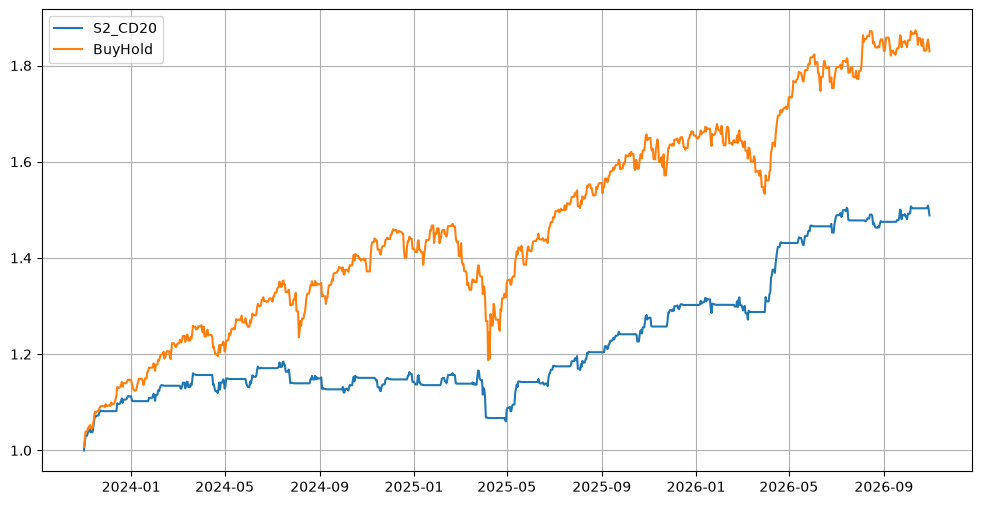

In [31]:
# 最もパフォーマンスの高い戦略のバックテスト結果を可視化する
best_name = (top_strategy["strategy"])
# 最もパフォーマンスの高い戦略の名前を取得
position = (signal_df[best_name])
# ポジション情報を取得
turnover = (position.diff().abs().fillna(0))
# 売買回転率を計算
strategy_ret = (position * signal_df["GSPC_LOG_RET"] - turnover * cost)
# 戦略のリターンを計算
strategy_curve = np.exp(strategy_ret.cumsum())
# 買い持ちのリターンを計算
buyhold_curve = np.exp(signal_df["GSPC_LOG_RET"].cumsum())
# バックテスト結果をプロット
plt.figure(figsize=(12,6))
plt.plot(strategy_curve, label=best_name)
plt.plot(buyhold_curve, label="BuyHold")
plt.legend()
plt.grid()
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"8_Equity_Curves_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(str(output_path), dpi=300, bbox_inches='tight')
# 保存完了のメッセージを表示
print("saved:", output_path)
# グラフを表示
plt.show()

#### 9. Final Dashboard

In [32]:
dashboard = {
    "BestStrategy": backtest_df.sort_values("final_value",ascending=False).iloc[0]["strategy"],
    "BestEquity": backtest_df["final_value"].max(),
    "TradeCount": backtest_df.sort_values("final_value", ascending=False).iloc[0]["trade_count"],
    "BuyHold": buyhold
}
pd.Series(dashboard)

BestStrategy     S2_CD20
BestEquity      1.488456
TradeCount            53
BuyHold         1.829409
dtype: object

# Filter Verification V4.1 レポート

## 検証目的

V1〜V4の検証により、

```text
HYG_LOG_RET
HY_OAS_CHANGE
```

がフィルタリングされた市場状態系列に対して統計的に有意な説明力を持つ可能性が確認された。

本フェーズでは、

```text
・説明変数の頑健性確認
・単独シグナルと複合シグナルの比較
・市場状態説明力の評価
・実運用環境における挙動確認
```

を目的として検証を実施した。

---

## 検証手法

以下の4種類の説明変数構成を評価した。

```text
S1 : HY_OAS_CHANGE単独

S2 : HYG_LOG_RET単独

S3 : HY_OAS_CHANGE
     AND
     HYG_LOG_RET

S4 : スコア型複合モデル
```

さらに、

```text
0営業日
3営業日
5営業日
10営業日
20営業日
```

のクールダウン期間を導入し、シグナルの安定性と売買頻度の変化を比較した。

評価対象は売買パフォーマンスだけでなく、

```text
説明変数としての安定性
シグナルの冗長性
売買頻度
```

も含むものとした。

---

## 主な結果

最も安定した結果を示した構成は、

```text
S2_CD20

(HYG_LOG_RET単独
+20営業日クールダウン)
```

であった。

結果は

```text
最終資産額      1.488

取引回数          53回

平均Turnover    0.048
```

となった。

比較対象の Buy & Hold は

```text
1.829
```

であった。

一方、

```text
HY_OAS_CHANGE
+
HYG_LOG_RET
```

による複合シグナルは、HYG単独を上回らなかった。

---

## 考察

本検証において重要なのは、

```text
複合シグナルが
単独HYGを上回らなかった
```

ことである。

この結果は、

```text
HYG_LOG_RET
```

が市場状態を説明する主要な説明変数である可能性を示唆する。

一方、

```text
HY_OAS_CHANGE
```

は過去の検証において

```text
Lead-Lag優位
Granger因果性
```

を示しており、市場状態への先行シグナルとしての価値を保持している。

したがって両者は競合する説明変数ではなく、

```text
HYG_LOG_RET
= 同時的な市場状態の説明

HY_OAS_CHANGE
= 市場状態への先行シグナル
```

として異なる役割を担っている可能性が高い。

---

## 結論

本検証の目的は、

```text
売買戦略の最適化
```

ではなく、

```text
フィルタリングされた株価指数系列を説明する
頑健な説明変数の探索
```

であった。

この観点では、

```text
HYG_LOG_RET
```

は引き続き最も安定した説明変数として確認された。

また、

```text
HY_OAS_CHANGE
```

についても、過去フェーズで確認された先行性および因果性を否定する結果は得られなかった。

したがって現時点では、

> **S&P500を構成する変動要因のうち、信用市場に由来する成分を部分的に分離し、その成分を説明する有力な説明変数として HYG_LOG_RET と HY_OAS_CHANGE を特定できた。**

と結論付けることが妥当である。

今後は売買戦略の最適化よりも、

```text
信用市場成分

＋

流動性成分

＋

大型テック主導成分
```

を統合したマルチファクターモデルの構築、および市場状態（Market State Indicator）の定量化へ研究を発展させることが有望と考えられる。